In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('data/spotify-tracks-dataset.csv')

In [3]:
df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [4]:
# EDA + preprocessing + a working baseline, with early results. Multiple models trained (preliminary version).
df.shape

(114000, 21)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu

In [6]:
df.describe()

,Unnamed: 0,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,114000.000000,114000.000000,1.140000e+05,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000
mean,56999.500000,33.238535,2.280292e+05,0.566800,0.641383,5.309140,-8.258960,0.637553,0.084652,0.314910,0.156050,0.213553,0.474068,122.147837,3.904035
std,32909.109681,22.305078,1.072977e+05,0.173542,0.251529,3.559987,5.029337,0.480709,0.105732,0.332523,0.309555,0.190378,0.259261,29.978197,0.432621
min,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,28499.750000,17.000000,1.740660e+05,0.456000,0.472000,2.000000,-10.013000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.218750,4.000000
50%,56999.500000,35.000000,2.129060e+05,0.580000,0.685000,5.000000,-7.004000,1.000000,0.048900,0.169000,0.000042,0.132000,0.464000,122.017000,4.000000
75%,85499.250000,50.000000,2.615060e+05,0.695000,0.854000,8.000000,-5.003000,1.000000,0.084500,0.598000,0.049000,0.273000,0.683000,140.071000,4.000000
max,113999.000000,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


In [7]:
df['track_genre'].unique().count()

np.int64(114)

In [8]:
genre_map = {
    # Rock / Punk / Metal
    'alt-rock': 'rock_metal', 'alternative': 'rock_metal', 'grunge': 'rock_metal',
    'hard-rock': 'rock_metal', 'psych-rock': 'rock_metal', 'rock': 'rock_metal',
    'rock-n-roll': 'rock_metal', 'rockabilly': 'rock_metal', 'j-rock': 'rock_metal',
    'guitar': 'rock_metal', 'british': 'rock_metal',
    'punk': 'rock_metal', 'punk-rock': 'rock_metal', 'emo': 'rock_metal',
    'hardcore': 'rock_metal', 'goth': 'rock_metal',
    'black-metal': 'rock_metal', 'death-metal': 'rock_metal', 'grindcore': 'rock_metal',
    'heavy-metal': 'rock_metal', 'metal': 'rock_metal', 'metalcore': 'rock_metal',
    'industrial': 'rock_metal',

    # Electronic / Bass / Dance
    'chicago-house': 'electronic_dance', 'deep-house': 'electronic_dance',
    'house': 'electronic_dance', 'progressive-house': 'electronic_dance',
    'detroit-techno': 'electronic_dance', 'minimal-techno': 'electronic_dance',
    'techno': 'electronic_dance', 'trance': 'electronic_dance',
    'hardstyle': 'electronic_dance', 'electro': 'electronic_dance',
    'electronic': 'electronic_dance', 'edm': 'electronic_dance',
    'idm': 'electronic_dance', 'garage': 'electronic_dance',
    'breakbeat': 'electronic_dance', 'drum-and-bass': 'electronic_dance',
    'dub': 'electronic_dance', 'dubstep': 'electronic_dance',
    'trip-hop': 'electronic_dance',
    'dance': 'electronic_dance', 'club': 'electronic_dance',
    'disco': 'electronic_dance', 'j-dance': 'electronic_dance',
    'party': 'electronic_dance',

    # Chill / Jazz / Classical
    'ambient': 'chill_jazz_classical', 'chill': 'chill_jazz_classical',
    'new-age': 'chill_jazz_classical', 'sleep': 'chill_jazz_classical',
    'study': 'chill_jazz_classical', 'sad': 'chill_jazz_classical',
    'piano': 'chill_jazz_classical',
    'jazz': 'chill_jazz_classical', 'blues': 'chill_jazz_classical',
    'classical': 'chill_jazz_classical', 'opera': 'chill_jazz_classical',
    'show-tunes': 'chill_jazz_classical',

    # Pop
    'pop': 'pop', 'pop-film': 'pop', 'power-pop': 'pop',
    'synth-pop': 'pop', 'indie-pop': 'pop', 'j-pop': 'pop',
    'k-pop': 'pop', 'cantopop': 'pop', 'mandopop': 'pop',
    'j-idol': 'pop', 'anime': 'pop', 'romance': 'pop', 'happy': 'pop',

    # Indie / Folk / Singer-songwriter
    'indie': 'indie_folk', 'singer-songwriter': 'indie_folk',
    'songwriter': 'indie_folk', 'folk': 'indie_folk', 'acoustic': 'indie_folk',

    # Hip-hop / R&B / Soul / Funk
    'hip-hop': 'hiphop_rnb', 'r-n-b': 'hiphop_rnb', 'soul': 'hiphop_rnb',
    'funk': 'hiphop_rnb', 'groove': 'hiphop_rnb', 'gospel': 'hiphop_rnb',

    # Country
    'country': 'country', 'bluegrass': 'country', 'honky-tonk': 'country',

    # Latin
    'latin': 'latin', 'latino': 'latin', 'spanish': 'latin',
    'salsa': 'latin', 'tango': 'latin', 'reggaeton': 'latin',
    'brazil': 'latin', 'forro': 'latin', 'mpb': 'latin',
    'pagode': 'latin', 'samba': 'latin', 'sertanejo': 'latin',

    # Reggae / Caribbean
    'reggae': 'reggae', 'dancehall': 'reggae', 'ska': 'reggae',

    # World
    'afrobeat': 'world', 'indian': 'world', 'iranian': 'world',
    'malay': 'world', 'turkish': 'world', 'world-music': 'world',
    'french': 'world', 'german': 'world', 'swedish': 'world',

    # Kids / Novelty
    'children': 'kids', 'kids': 'kids', 'disney': 'kids', 'comedy': 'kids',
}

In [9]:
df['genre_group'] = df['track_genre'].map(genre_map)

In [10]:
df['genre_group'].unique().count()

np.int64(11)

In [11]:
df.columns

Index(['Unnamed: 0', 'track_id', 'artists', 'album_name', 'track_name',
       'popularity', 'duration_ms', 'explicit', 'danceability', 'energy',
       'key', 'loudness', 'mode', 'speechiness', 'acousticness',
       'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature',
       'track_genre', 'genre_group'],
      dtype='str')

In [12]:
df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,genre_group
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic,indie_folk
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic,indie_folk
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic,indie_folk
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic,indie_folk
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic,indie_folk


In [13]:
# understanding missing values
print(df[df.isnull().any(axis=1)])

       Unnamed: 0                track_id artists album_name track_name  \
65900       65900  1kR4gIb7nGxHPI3D2ifs59     NaN        NaN        NaN   

       popularity  duration_ms  explicit  danceability  energy  ...  mode  \
65900           0            0     False         0.501   0.583  ...     0   

       speechiness  acousticness  instrumentalness  liveness  valence  \
65900       0.0605          0.69           0.00396    0.0747    0.734   

         tempo  time_signature  track_genre  genre_group  
65900  138.391               4        k-pop          pop  

[1 rows x 22 columns]


In [14]:
# since there is only one null value row, it is best to just drop that
old_len = df.shape[0]
print(old_len)
df = df.dropna()
print(f"Number of dropped rows: {old_len - len(df)}")

114000
Number of dropped rows: 1


In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
df['genre_group'].value_counts()

genre_group
electronic_dance        24000
rock_metal              23000
pop                     12999
chill_jazz_classical    12000
latin                   12000
world                    9000
hiphop_rnb               6000
indie_folk               5000
kids                     4000
country                  3000
reggae                   3000
Name: count, dtype: int64

In [17]:
df['track_id'].value_counts()

track_id
6S3JlDAGk3uu3NtZbPnuhS    9
2kkvB3RNRzwjFdGhaUA0tz    8
2Ey6v4Sekh3Z0RUSISRosD    8
2vU6bm5hVF2idVknGzqyPL    7
4GPQDyw9hC1DiZVh0ouDVL    7
                         ..
2C3TZjDRiAzdyViavDJ217    1
1hIz5L4IB9hN3WRYPOCGPw    1
6x8ZfSoqDjuNa5SVP5QjvX    1
2e6sXL2bYv4bSz6VTdnfLs    1
2hETkH7cOfqmz3LqZDHZf5    1
Name: count, Length: 89740, dtype: int64

In [22]:
import seaborn as sns

df_danceability = df.groupby('genre_group')['danceability'].median()
df_danceability

genre_group
chill_jazz_classical    0.4750
country                 0.5550
electronic_dance        0.6510
hiphop_rnb              0.6310
indie_folk              0.5670
kids                    0.6400
latin                   0.6430
pop                     0.5640
reggae                  0.7095
rock_metal              0.4920
world                   0.5790
Name: danceability, dtype: float64

<Axes: xlabel='genre_group', ylabel='danceability'>

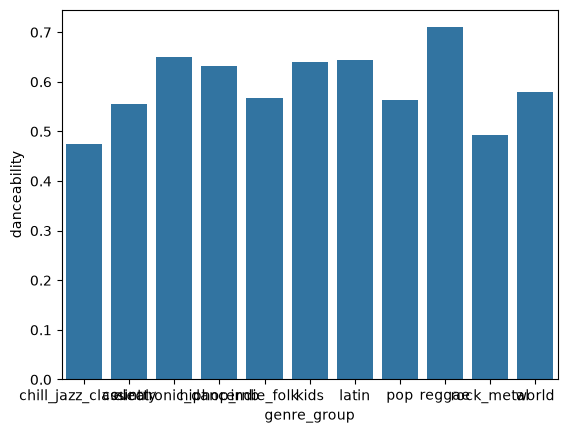

In [23]:
sns.barplot(df_danceability)